In [28]:
import pandas as pd
import numpy as np

df = pd.read_csv('../data/hhs_filled.csv', index_col='Date', parse_dates=True)
target = 'Children in HHS Care'

break_date = '2025-02-01'
series = df[target]

# Reserve the last 90 days of post-break data as the final held-out test set
test_start = series.index.max() - pd.Timedelta(days=90)
train = series[:test_start - pd.Timedelta(days=1)]
test = series[test_start:]

len(train), len(test), test.index.min(), test.index.max()

(984, 91, Timestamp('2025-09-22 00:00:00'), Timestamp('2025-12-21 00:00:00'))

In [29]:
def walk_forward_eval(series, model_fn, horizon, window_start, step=7):
    """
    model_fn(history) -> forecast array of length `horizon`
    Walks forward through `series` from window_start, forecasting `horizon` days
    at a time, stepping `step` days between folds.
    """
    results = []
    idx = series.index.get_loc(window_start)
    while idx + horizon <= len(series):
        history = series.iloc[:idx]
        actual = series.iloc[idx: idx + horizon]
        pred = model_fn(history, horizon)
        results.append(pd.DataFrame({'date': actual.index, 'actual': actual.values,
                                      'pred': pred, 'horizon': range(1, horizon+1)}))
        idx += step
    return pd.concat(results, ignore_index=True)

In [30]:
def naive_persistence(history, horizon):
    return np.repeat(history.iloc[-1], horizon)

def moving_average(history, horizon, window=7):
    return np.repeat(history.iloc[-window:].mean(), horizon)

In [31]:
from statsmodels.tsa.arima.model import ARIMA

def arima_forecast(history, horizon, order=(2,1,2)):
    model = ARIMA(history, order=order).fit()
    return model.forecast(horizon).values

In [32]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def holt_winters_forecast(history, horizon):
    model = ExponentialSmoothing(history, trend='add', damped_trend=True).fit()
    return model.forecast(horizon).values

In [33]:
models = {
    'naive': naive_persistence,
    'moving_avg': moving_average,
    'arima': arima_forecast,
    'holt_winters': holt_winters_forecast,
}

all_results = {}
for h in [1, 7, 14]:
    for name, fn in models.items():
        all_results[(name, h)] = walk_forward_eval(series, fn, horizon=h, window_start=test_start)

/home/abhinav/miniconda3/envs/uac-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/abhinav/miniconda3/envs/uac-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/abhinav/miniconda3/envs/uac-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/abhinav/miniconda3/envs/uac-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/abhinav/miniconda3/envs/uac-forecast/lib/python3.11/site-p

In [34]:
def mape(actual, pred):
    return np.mean(np.abs((actual - pred) / actual)) * 100

rows = []
for (name, h), res in all_results.items():
    mae = np.mean(np.abs(res['actual'] - res['pred']))
    rmse = np.sqrt(np.mean((res['actual'] - res['pred'])**2))
    mp = mape(res['actual'], res['pred'])
    rows.append({'model': name, 'horizon': h, 'MAE': mae, 'RMSE': rmse, 'MAPE': mp})

scoreboard = pd.DataFrame(rows).sort_values(['horizon', 'MAE'])
scoreboard

,model,horizon,MAE,RMSE,MAPE
2,arima,1,5.225551,5.908363,0.225747
3,holt_winters,1,5.244577,6.429388,0.225450
0,naive,1,5.750000,6.403500,0.250053
1,moving_avg,1,20.467033,21.625623,0.893203
7,holt_winters,7,10.306155,13.409494,0.450412
4,naive,7,14.425824,18.157996,0.626325
6,arima,7,15.885253,19.822494,0.688792
5,moving_avg,7,29.877551,32.356634,1.296790
11,holt_winters,14,17.701853,23.043673,0.770189
8,naive,14,28.181548,34.333089,1.219256


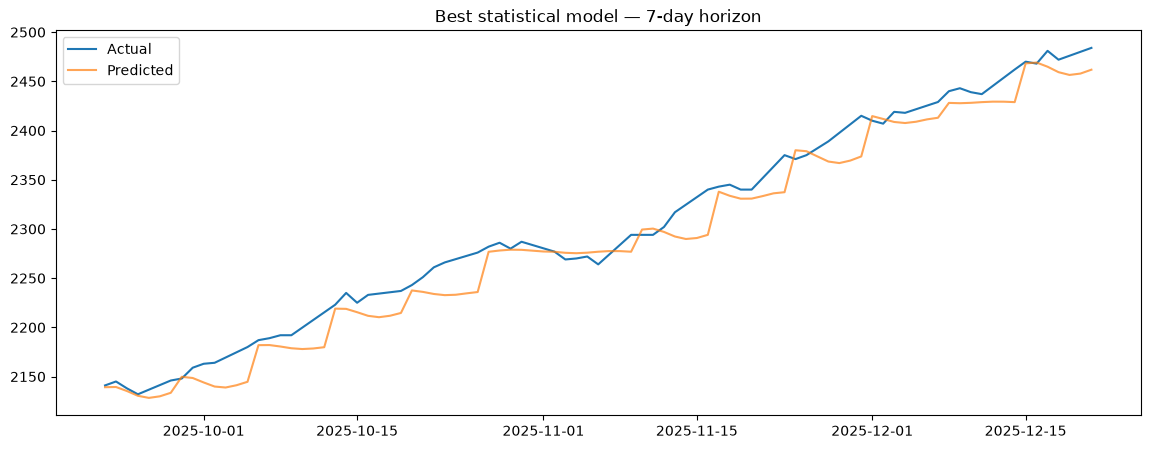

In [35]:
import matplotlib.pyplot as plt

best = all_results[('arima', 7)]  # swap for whichever wins
fig, ax = plt.subplots(figsize=(14,5))
ax.plot(best['date'], best['actual'], label='Actual')
ax.plot(best['date'], best['pred'], label='Predicted', alpha=0.7)
ax.legend(); ax.set_title('Best statistical model — 7-day horizon')
plt.savefig('../outputs/figures/arima_vs_actual.png')
plt.show()

In [36]:
scoreboard.to_csv('../outputs/statistical_scoreboard.csv', index=False)

## Statistical Modeling Summary

- **Setup:** trained on full history, evaluated via 7-day-step walk-forward on the last 90 days (entirely post-break).
- **1-day horizon:** ARIMA and Holt-Winters tie (~MAE 5.2), both beat naive persistence (5.75).
- **7-day and 14-day horizons:** Holt-Winters (damped trend) wins clearly (MAE 10.3 / 17.7). ARIMA(2,1,2) underperforms naive persistence at these horizons — its fixed order isn't tuned for longer-range drift.
- **Moving average is worst at every horizon** — a flat 7-day average can't track the trend.
- **Takeaway:** damped-trend exponential smoothing is the strongest statistical baseline here. ARIMA order should be tuned (e.g. via `auto_arima`) before being trusted past 1-day horizons; as-is it's not reliable competition for the simpler model.
- **Carried forward:** `holt_winters` is the statistical model to beat in Phase 4 (ML models).